# Landmark Recognition Using the SIFT Algorithm
**Python + OpenCV | Google Colab ready – just click *Runtime → Run all*.**

The notebook builds its own landmark database (it downloads photos from Wikimedia Commons; if the internet/download fails it automatically falls back to generated landmark images, so it never crashes), then performs:

1. Task 1 – Landmark image database
2. Task 2 – SIFT feature extraction
3. Task 3 – Query image processing
4. Task 4 – BF matching + KNN (k=2) + Lowe's ratio test + recognition decision
5. Task 5 – Localization with RANSAC homography
6. Task 6 – Performance evaluation table

In [1]:
# ============ 0. IMPORTS & CONFIGURATION ============
import os, cv2, time, zlib, pickle, shutil, urllib.parse
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
assert hasattr(cv2, "SIFT_create"), "SIFT not available in this OpenCV build"

ROOT      = "landmark_project"
DB_DIR    = f"{ROOT}/database"     # reference images, one folder per landmark
QUERY_DIR = f"{ROOT}/queries"      # held-out query images
OUT_DIR   = f"{ROOT}/outputs"      # screenshots, csv, pickle
for d in (DB_DIR, QUERY_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

# ---- parameters ----
MAX_DIM          = 800    # resize big images for speed
RATIO            = 0.75   # Lowe's ratio threshold
MIN_GOOD         = 15     # min reliable matches to even consider a landmark
MIN_INLIERS      = 12     # min RANSAC inliers for geometric verification
MIN_INLIER_RATIO = 0.25   # inliers / reliable matches
MARGIN           = 1.5    # best landmark must have >= 1.5x inliers of runner-up
RANSAC_THRESH    = 5.0    # pixels
DRAW_RICH        = False  # True = draw keypoint size/orientation circles

plt.rcParams["figure.dpi"] = 100

OpenCV version: 4.14.0


## Task 1 – Landmark Image Database

In [2]:
# 5 landmarks in the database + 1 "unknown" landmark (NOT stored in the database) for rejection tests
LANDMARKS = {
    "Eiffel_Tower": ["Tour_Eiffel_Wikimedia_Commons.jpg", "Eiffel_Tower_20051010.jpg",
                     "Tour_Eiffel_Wikimedia_Commons_(cropped).jpg", "Eiffel_Tower_in_Paris.jpg"],
    "Taj_Mahal": ["Taj_Mahal,_Agra,_India_edit3.jpg", "Taj_Mahal_(Edited).jpeg",
                  "Taj_Mahal_in_March_2004.jpg", "Taj_Mahal_2012.jpg"],
    "Colosseum": ["Colosseum_in_Rome,_Italy_-_April_2007.jpg", "Colosseo_2020.jpg",
                  "Rome_Colosseum.jpg", "Colosseum_Rome_2012.jpg"],
    "Statue_of_Liberty": ["Statue_of_Liberty,_NY.jpg", "Statue_of_Liberty_7.jpg",
                          "Statue_of_Liberty_from_the_Liberty_State_Park.jpg", "Statue_of_Liberty_2010.jpg"],
    "Great_Wall_of_China": ["The_Great_Wall_of_China_at_Jinshanling-edit.jpg", "20090529_Great_Wall_8185.jpg",
                            "Great_Wall_of_China_July_2006.JPG", "GreatWall_2004_Summer_4.jpg"],
}
UNKNOWN_NAME  = "Pyramids_of_Giza"
UNKNOWN_FILES = ["Kheops-Pyramid.jpg", "All_Gizah_Pyramids.jpg"]

HEADERS = {"User-Agent": "Mozilla/5.0 (SIFT-LandmarkLab/1.0; educational Colab notebook)"}

def resize_max(img, max_dim=MAX_DIM):
    h, w = img.shape[:2]
    s = max_dim / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    return img

def download_commons(filename, width=900):
    """Download an image from Wikimedia Commons. Returns BGR image or None."""
    url = "https://commons.wikimedia.org/wiki/Special:FilePath/" + urllib.parse.quote(filename) + f"?width={width}"
    for attempt in range(2):
        try:
            r = requests.get(url, headers=HEADERS, timeout=20)
            if r.status_code == 200 and len(r.content) > 5000:
                img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
                if img is not None and min(img.shape[:2]) >= 200:
                    return resize_max(img)
            elif r.status_code == 429:
                time.sleep(2)
        except Exception:
            pass
        time.sleep(0.5)
    return None

# ---------- augmentation helpers (also used in Task 6) ----------
def rotate(img, deg):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

def resize_scale(img, s):
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)

def darken(img, alpha=0.4):
    return cv2.convertScaleAbs(img, alpha=alpha, beta=-10)

def persp(img, k=1.0, side="left"):
    """Simulate a different viewpoint with a perspective warp."""
    h, w = img.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    if side == "left":
        dst = np.float32([[0.10*k*w, 0.07*k*h], [w, 0], [w, h], [0, (1-0.07*k)*h]])
    else:
        dst = np.float32([[0, 0], [(1-0.10*k)*w, 0.07*k*h], [(1-0.10*k)*w, (1-0.07*k)*h], [0, h]])
    M = cv2.getPerspectiveTransform(src, dst)
    return cv2.warpPerspective(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

def zoom_crop(img, z=1.6):
    h, w = img.shape[:2]
    ch, cw = int(h / z), int(w / z)
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    return cv2.resize(img[y0:y0+ch, x0:x0+cw], (w, h), interpolation=cv2.INTER_CUBIC)

# ---------- fallback: procedurally generated landmark images (used only if download fails) ----------
def synth_landmark(name, view, size=(640, 480)):
    seed = zlib.crc32(name.encode()) % (2**31 - 1)
    rng = np.random.RandomState(seed)
    T = 480
    tex = np.zeros((T, T, 3), np.uint8) + rng.randint(60, 200, 3).astype(np.uint8)
    for _ in range(400):
        x, y = rng.randint(0, T, 2); w, h = rng.randint(8, 60, 2)
        col = tuple(int(c) for c in rng.randint(0, 255, 3))
        if rng.rand() < 0.5: cv2.rectangle(tex, (int(x), int(y)), (int(x+w), int(y+h)), col, -1)
        else:                cv2.circle(tex, (int(x), int(y)), int(w//2)+3, col, -1)
    for _ in range(80):
        p1 = tuple(int(v) for v in rng.randint(0, T, 2)); p2 = tuple(int(v) for v in rng.randint(0, T, 2))
        cv2.line(tex, p1, p2, tuple(int(c) for c in rng.randint(0, 255, 3)), int(rng.randint(1, 4)))
    tex = cv2.GaussianBlur(tex, (3, 3), 0)
    mask = np.zeros((T, T), np.uint8)
    top = int(rng.randint(40, 200))
    poly = np.array([[T//2 - top//2, 20], [T//2 + top//2, 20], [T - 40, T - 20], [40, T - 20]], np.int32)
    cv2.fillConvexPoly(mask, poly, 255)

    rv = np.random.RandomState(seed + 101 * (view + 1))
    s = rv.uniform(0.7, 1.1)
    cx, cy = size[0] / 2 + rv.uniform(-40, 40), size[1] / 2 + rv.uniform(-20, 20)
    half = T * s / 2 * 0.9
    src = np.float32([[0, 0], [T, 0], [T, T], [0, T]])
    dst = np.float32([[cx-half, cy-half], [cx+half, cy-half], [cx+half, cy+half], [cx-half, cy+half]])
    dst += rv.uniform(-25, 25, (4, 2)).astype(np.float32)
    M = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(tex, M, size)
    wm = cv2.warpPerspective(mask, M, size)
    # background: gradient + blurred random clutter (different for every view)
    bg = np.zeros((size[1], size[0], 3), np.uint8)
    grad = np.linspace(rv.randint(120, 255), rv.randint(60, 200), size[1]).astype(np.uint8)
    bg[:] = grad[:, None, None]
    for _ in range(25):
        x, y = rv.randint(0, size[0]), rv.randint(0, size[1])
        cv2.circle(bg, (int(x), int(y)), int(rv.randint(5, 40)), tuple(int(c) for c in rv.randint(0, 255, 3)), -1)
    bg = cv2.GaussianBlur(bg, (15, 15), 0)
    return np.where(wm[..., None] > 0, warped, bg).astype(np.uint8)

# ---------- build the database ----------
def collect_images(name, files, want=3):
    imgs = []
    for f in files:
        img = download_commons(f)
        if img is not None:
            imgs.append(img)
        if len(imgs) >= want:
            break
    return imgs

SOURCE = {}          # landmark -> "wikimedia" / "partly synthetic" / "synthetic"
QUERY_BASE = {}      # landmark -> held-out query image path

if os.path.exists(ROOT):
    shutil.rmtree(ROOT)
for d in (DB_DIR, QUERY_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

for name, files in LANDMARKS.items():
    imgs = collect_images(name, files, want=3)
    src = "wikimedia"
    if len(imgs) >= 2:
        query_img, refs = imgs[-1], imgs[:-1]
    elif len(imgs) == 1:
        refs = imgs[:]; query_img = persp(zoom_crop(imgs[0], 1.15), 0.4, "right"); src = "wikimedia (1 photo + augmentations)"
    else:
        refs = [synth_landmark(name, 0), synth_landmark(name, 1)]
        query_img = synth_landmark(name, 2); src = "synthetic (download unavailable)"
    # extra references with different distance / viewing angle so every landmark has >= 4 images
    refs = refs + [zoom_crop(refs[0], 1.6), persp(refs[0], 0.8, "left")]
    os.makedirs(f"{DB_DIR}/{name}", exist_ok=True)
    for i, im in enumerate(refs, 1):
        cv2.imwrite(f"{DB_DIR}/{name}/{name}_{i:02d}.jpg", im)
    qp = f"{QUERY_DIR}/{name}_query.jpg"
    cv2.imwrite(qp, query_img)
    QUERY_BASE[name] = qp
    SOURCE[name] = src

# unknown landmark (never added to the database)
unk = collect_images(UNKNOWN_NAME, UNKNOWN_FILES, want=1)
if unk:
    unk_img, unk_src = unk[0], "wikimedia"
else:
    unk_img, unk_src = synth_landmark(UNKNOWN_NAME, 0), "synthetic (download unavailable)"
cv2.imwrite(f"{QUERY_DIR}/{UNKNOWN_NAME}_query.jpg", unk_img)

print("DATABASE STRUCTURE")
for name in LANDMARKS:
    fl = sorted(os.listdir(f"{DB_DIR}/{name}"))
    print(f"  {name:22s} {len(fl)} images   [{SOURCE[name]}]")
print(f"  (unknown test landmark: {UNKNOWN_NAME} [{unk_src}] - not in database)")

DATABASE STRUCTURE
  Eiffel_Tower           4 images   [wikimedia]
  Taj_Mahal              4 images   [wikimedia]
  Colosseum              4 images   [wikimedia]
  Statue_of_Liberty      3 images   [wikimedia]
  Great_Wall_of_China    4 images   [wikimedia]
  (unknown test landmark: Pyramids_of_Giza [wikimedia] - not in database)


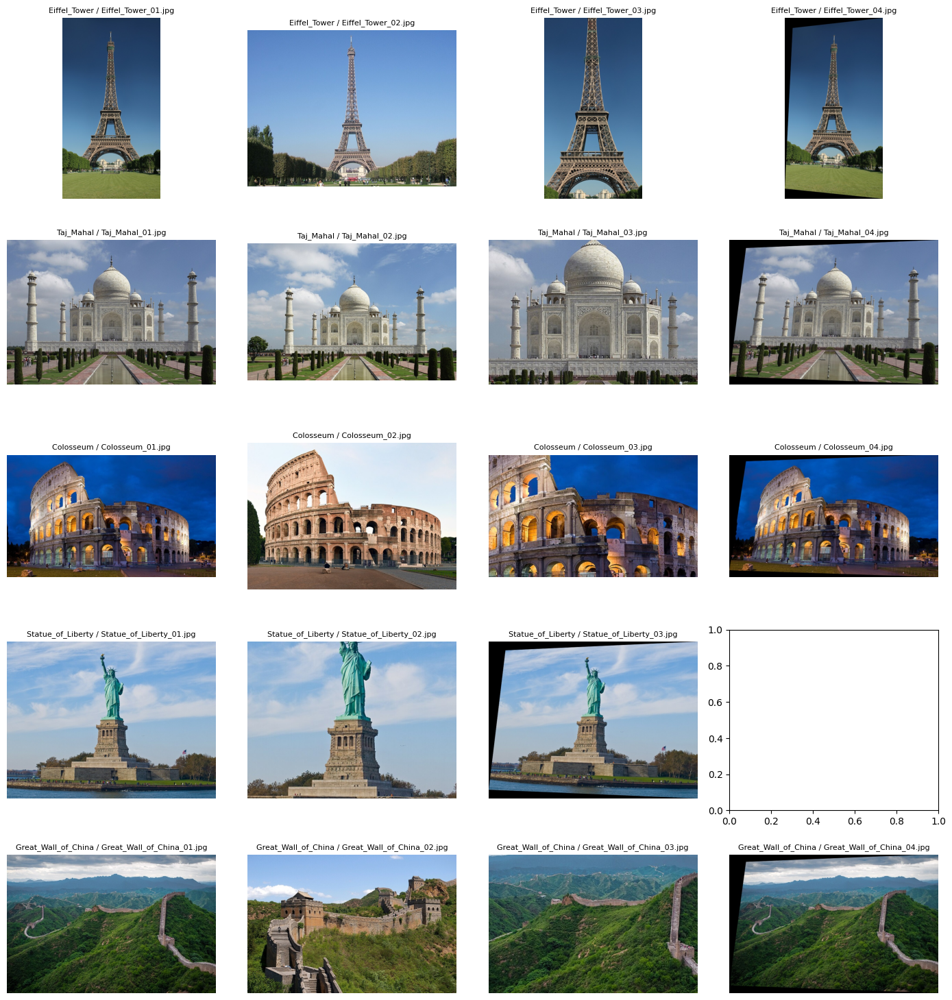

In [3]:
# Show a sample of the database
fig, axes = plt.subplots(len(LANDMARKS), 4, figsize=(14, 3.0 * len(LANDMARKS)))
for r, name in enumerate(LANDMARKS):
    for c, fn in enumerate(sorted(os.listdir(f"{DB_DIR}/{name}"))[:4]):
        im = cv2.imread(f"{DB_DIR}/{name}/{fn}")
        axes[r, c].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[r, c].axis("off")
        axes[r, c].set_title(f"{name} / {fn}", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task1_database.png", dpi=100); plt.show()

## Task 2 – SIFT Feature Extraction (reference images)

In [4]:
sift = cv2.SIFT_create()

def extract_sift(img_bgr):
    """grayscale -> SIFT keypoints + 128-D descriptors"""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    return gray, list(kp), des

DATABASE = []   # list of dicts: landmark, path, img, kp, des
for name in LANDMARKS:
    for fn in sorted(os.listdir(f"{DB_DIR}/{name}")):
        path = f"{DB_DIR}/{name}/{fn}"
        img = cv2.imread(path)
        if img is None:
            continue
        img = resize_max(img)
        gray, kp, des = extract_sift(img)
        if des is None or len(kp) < 2:
            print("  skipped (no features):", path); continue
        DATABASE.append(dict(landmark=name, path=path, img=img, kp=kp, des=des))

# store descriptors + labels on disk (cv2.KeyPoint is not picklable -> store as tuples)
store = [dict(landmark=e["landmark"], path=e["path"], des=e["des"],
              kp=[(k.pt, k.size, k.angle, k.response, k.octave, k.class_id) for k in e["kp"]]) for e in DATABASE]
with open(f"{OUT_DIR}/sift_database.pkl", "wb") as f:
    pickle.dump(store, f)

summary = pd.DataFrame([dict(Landmark=e["landmark"], Image=os.path.basename(e["path"]),
                             Keypoints=len(e["kp"]), Descriptor_shape=str(e["des"].shape)) for e in DATABASE])
display(summary) if "display" in globals() else print(summary)
print("Total reference images:", len(DATABASE), "| descriptors saved to", f"{OUT_DIR}/sift_database.pkl")

               Landmark                       Image  Keypoints  \
0          Eiffel_Tower         Eiffel_Tower_01.jpg       1201   
1          Eiffel_Tower         Eiffel_Tower_02.jpg       1523   
2          Eiffel_Tower         Eiffel_Tower_03.jpg       3662   
3          Eiffel_Tower         Eiffel_Tower_04.jpg       1533   
4             Taj_Mahal            Taj_Mahal_01.jpg       1753   
5             Taj_Mahal            Taj_Mahal_02.jpg       1660   
6             Taj_Mahal            Taj_Mahal_03.jpg       4754   
7             Taj_Mahal            Taj_Mahal_04.jpg       2060   
8             Colosseum            Colosseum_01.jpg       2235   
9             Colosseum            Colosseum_02.jpg       2986   
10            Colosseum            Colosseum_03.jpg       5062   
11            Colosseum            Colosseum_04.jpg       2338   
12    Statue_of_Liberty    Statue_of_Liberty_01.jpg       1274   
13    Statue_of_Liberty    Statue_of_Liberty_02.jpg       2392   
14    Stat

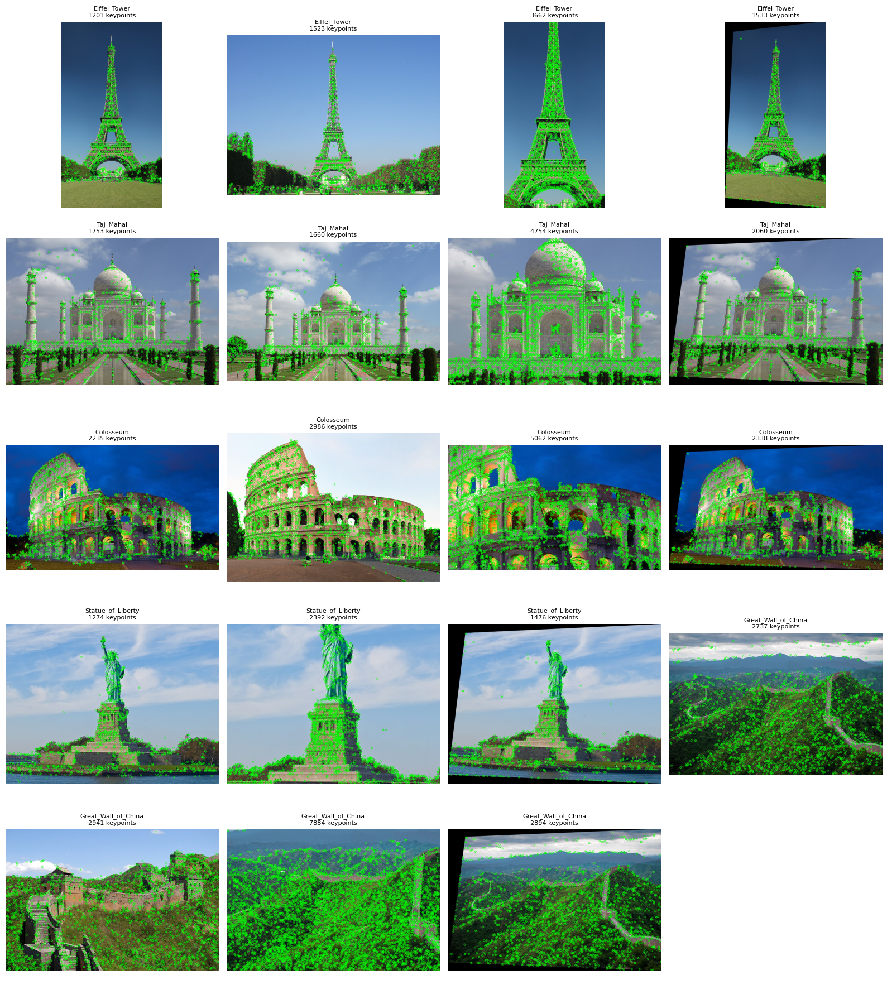

In [5]:
# Display reference images with their detected keypoints
flag = cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS if DRAW_RICH else cv2.DRAW_MATCHES_FLAGS_DEFAULT
cols = 4
rows = int(np.ceil(len(DATABASE) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 3.6 * rows))
axes = np.array(axes).reshape(-1)
for ax in axes: ax.axis("off")
for ax, e in zip(axes, DATABASE):
    vis = cv2.drawKeypoints(e["img"], e["kp"], None, color=(0, 255, 0), flags=flag)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{e["landmark"]}\n{len(e["kp"])} keypoints', fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task2_reference_keypoints.png", dpi=100); plt.show()

## Task 3 – Query Image Processing

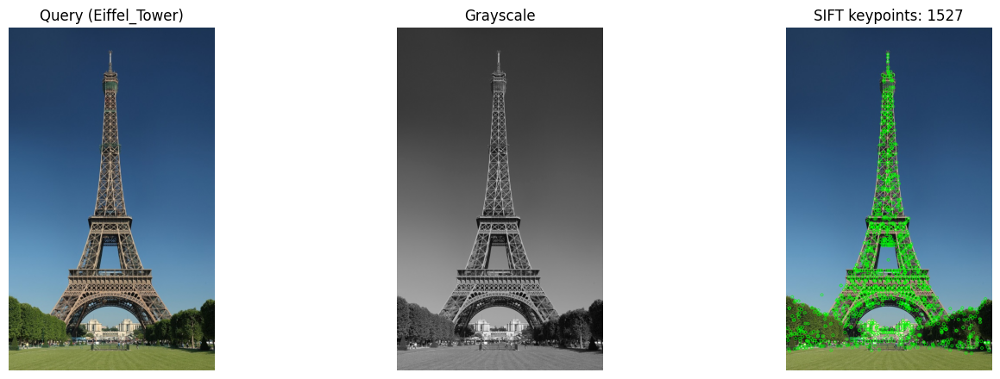

Descriptor matrix shape: (1527, 128)


In [6]:
def process_query(img_bgr):
    img = resize_max(img_bgr)
    gray, kp, des = extract_sift(img)
    return img, gray, kp, des

def show_query(img_bgr, title="Query image"):
    img, gray, kp, des = process_query(img_bgr)
    vis = cv2.drawKeypoints(img, kp, None, color=(0, 255, 0), flags=flag)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title(title)
    ax[1].imshow(gray, cmap="gray");                     ax[1].set_title("Grayscale")
    ax[2].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB));  ax[2].set_title(f"SIFT keypoints: {len(kp)}")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task3_query_keypoints.png", dpi=100); plt.show()
    print("Descriptor matrix shape:", None if des is None else des.shape)

demo_name = "Eiffel_Tower"
show_query(cv2.imread(QUERY_BASE[demo_name]), f"Query ({demo_name})")

## Task 4 & 5 – Matching, Recognition and Localization

In [7]:
bf = cv2.BFMatcher(cv2.NORM_L2)          # Brute-Force, Euclidean distance

def ratio_matches(des_q, des_r, ratio=RATIO):
    """KNN (k=2) + Lowe's ratio test. queryIdx -> query, trainIdx -> reference."""
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2:
        return []
    pairs = bf.knnMatch(des_q, des_r, k=2)
    good = []
    for p in pairs:
        if len(p) == 2 and p[0].distance < ratio * p[1].distance:
            good.append(p[0])
    return good

def polygon_ok(proj, q_shape):
    """Sanity checks for the projected reference-image corners."""
    if proj is None or not np.all(np.isfinite(proj)):
        return False
    poly = proj.astype(np.float32).reshape(-1, 1, 2)
    if not cv2.isContourConvex(poly):
        return False
    area = cv2.contourArea(poly)
    q_area = q_shape[0] * q_shape[1]
    if area < 0.01 * q_area or area > 10 * q_area:
        return False
    sides = np.linalg.norm(proj - np.roll(proj, -1, axis=0), axis=1)
    return bool(sides.min() > 10 and sides.max() / sides.min() < 30)

def verify_geometry(kp_q, kp_r, good, ref_shape, q_shape):
    """RANSAC homography reference -> query and projection of the 4 reference corners."""
    out = dict(H=None, inliers=0, mask=np.zeros(len(good), bool), proj=None, valid=False)
    if len(good) < 8:
        return out
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None or mask is None:
        return out
    h, w = ref_shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    try:
        proj = cv2.perspectiveTransform(corners, H).reshape(-1, 2)
    except cv2.error:
        proj = None
    out.update(H=H, inliers=int(mask.sum()), mask=mask.ravel().astype(bool), proj=proj,
               valid=polygon_ok(proj, q_shape))
    return out

def recognize(query_bgr):
    t0 = time.perf_counter()
    q_img, q_gray, kp_q, des_q = process_query(query_bgr)
    cands = []
    for name in LANDMARKS:
        best = None
        for e in (x for x in DATABASE if x["landmark"] == name):
            good = ratio_matches(des_q, e["des"])
            if best is None or len(good) > len(best["good"]):
                best = dict(entry=e, good=good)
        g = verify_geometry(kp_q, best["entry"]["kp"], best["good"], best["entry"]["img"].shape, q_img.shape)
        cands.append(dict(landmark=name, ref_path=best["entry"]["path"], ref_img=best["entry"]["img"],
                          ref_kp=best["entry"]["kp"], good=best["good"], n_good=len(best["good"]),
                          inliers=g["inliers"], inlier_mask=g["mask"], proj=g["proj"], valid=g["valid"],
                          ratio=g["inliers"] / max(len(best["good"]), 1)))
    ranked = sorted(cands, key=lambda c: c["n_good"], reverse=True)       # ranking by reliable matches

    # decision: geometric verification + threshold + margin (NOT just the largest match count)
    verified = [c for c in cands if c["valid"]]
    pick = max(verified, key=lambda c: c["inliers"]) if verified else ranked[0]
    others = [c["inliers"] for c in cands if c is not pick and c["valid"]]
    runner = max(others) if others else 0

    reason, recognized = "", False
    if pick["n_good"] < MIN_GOOD:
        reason = f"only {pick['n_good']} reliable matches (< {MIN_GOOD})"
    elif not pick["valid"]:
        reason = "geometric transformation unreliable (invalid polygon)"
    elif pick["inliers"] < MIN_INLIERS:
        reason = f"only {pick['inliers']} RANSAC inliers (< {MIN_INLIERS})"
    elif pick["ratio"] < MIN_INLIER_RATIO:
        reason = f"inlier ratio {pick['ratio']:.2f} too low (< {MIN_INLIER_RATIO})"
    elif runner > 0 and pick["inliers"] < MARGIN * runner:
        reason = f"ambiguous: runner-up has {runner} inliers"
    else:
        recognized = True
        reason = "passed match threshold, RANSAC and margin tests"

    return dict(query=q_img, kp_q=kp_q, n_kp=len(kp_q), ranked=ranked, best=pick,
                predicted=pick["landmark"] if recognized else "Unknown",
                top_candidate=pick["landmark"], recognized=recognized, reason=reason,
                n_good=pick["n_good"], n_inliers=pick["inliers"],
                time=time.perf_counter() - t0)

def annotate(res):
    """Query image with localized polygon (only if recognized & geometry valid) + status text."""
    vis = res["query"].copy()
    b = res["best"]
    if res["recognized"] and b["valid"]:
        cv2.polylines(vis, [np.int32(b["proj"]).reshape(-1, 1, 2)], True, (0, 0, 255), 4)
        txt = f'{res["predicted"]} | matches {res["n_good"]} | inliers {res["n_inliers"]}'
        cv2.rectangle(vis, (0, 0), (vis.shape[1], 30), (0, 0, 0), -1)
        cv2.putText(vis, txt, (8, 21), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    else:
        cv2.rectangle(vis, (0, 0), (vis.shape[1], 30), (0, 0, 0), -1)
        cv2.putText(vis, "REJECTED - no reliable localization", (8, 21), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    return vis

def show_result(res, title="", save_as=None):
    b = res["best"]
    kp_vis = cv2.drawKeypoints(res["query"], res["kp_q"], None, color=(0, 255, 0), flags=flag)
    # draw at most 80 matches (inliers first) so the picture stays readable; counts below are the full numbers
    order = np.argsort(~b["inlier_mask"]) if b["inlier_mask"].size else np.arange(len(b["good"]))
    shown = [b["good"][i] for i in order[:80]]
    match_vis = cv2.drawMatches(res["query"], res["kp_q"], b["ref_img"], b["ref_kp"], shown, None,
                                matchColor=(0, 255, 0), singlePointColor=None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    fig = plt.figure(figsize=(16, 9))
    ax1 = fig.add_subplot(2, 3, 1); ax1.imshow(cv2.cvtColor(res["query"], cv2.COLOR_BGR2RGB)); ax1.set_title("1. Query image")
    ax2 = fig.add_subplot(2, 3, 2); ax2.imshow(cv2.cvtColor(kp_vis, cv2.COLOR_BGR2RGB));       ax2.set_title(f'2. SIFT keypoints ({res["n_kp"]})')
    ax3 = fig.add_subplot(2, 3, 3); ax3.imshow(cv2.cvtColor(annotate(res), cv2.COLOR_BGR2RGB))
    ax3.set_title("6. Localized region" if res["recognized"] else "6. Localization (not drawn)")
    ax4 = fig.add_subplot(2, 1, 2); ax4.imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
    ax4.set_title(f'3. Matches with best candidate: {b["landmark"]}  (up to 80 lines shown, inliers first)')
    for a in (ax1, ax2, ax3, ax4): a.axis("off")
    status = "RECOGNIZED" if res["recognized"] else "REJECTED"
    fig.suptitle(f'{title}  ->  Predicted: {res["predicted"]} | Reliable matches: {res["n_good"]} | '
                 f'RANSAC inliers: {res["n_inliers"]} | {status} | {res["time"]:.2f}s', fontsize=11, fontweight="bold")
    plt.tight_layout()
    if save_as: plt.savefig(f"{OUT_DIR}/{save_as}", dpi=100)
    plt.show()
    print(pd.DataFrame([dict(Rank=i + 1, Landmark=c["landmark"], Reliable_matches=c["n_good"],
                             RANSAC_inliers=c["inliers"], Valid_geometry=c["valid"])
                        for i, c in enumerate(res["ranked"])]).to_string(index=False))
    print(f"\nDecision : {status}  ({res['reason']})")
    print(f"Predicted: {res['predicted']}   | Reliable matches: {res['n_good']} | Inliers: {res['n_inliers']}")
    if not res["recognized"]:
        print("Message  : Landmark rejected / geometric transformation unreliable - no polygon drawn.")

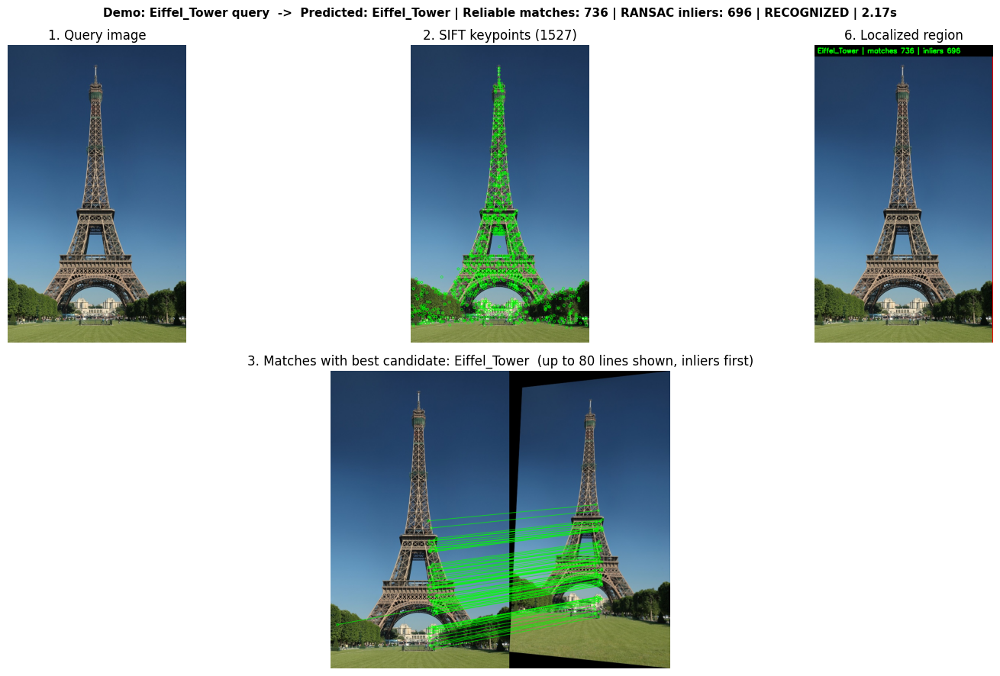

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1        Eiffel_Tower               736             696            True
    2           Taj_Mahal                 7               0           False
    3           Colosseum                 7               0           False
    4   Statue_of_Liberty                 7               0           False
    5 Great_Wall_of_China                 4               0           False

Decision : RECOGNIZED  (passed match threshold, RANSAC and margin tests)
Predicted: Eiffel_Tower   | Reliable matches: 736 | Inliers: 696


In [8]:
# ---------- DEMO 1: a known landmark ----------
q = cv2.imread(QUERY_BASE["Eiffel_Tower"])
res = recognize(q)
show_result(res, "Demo: Eiffel_Tower query", save_as="demo_recognized.png")

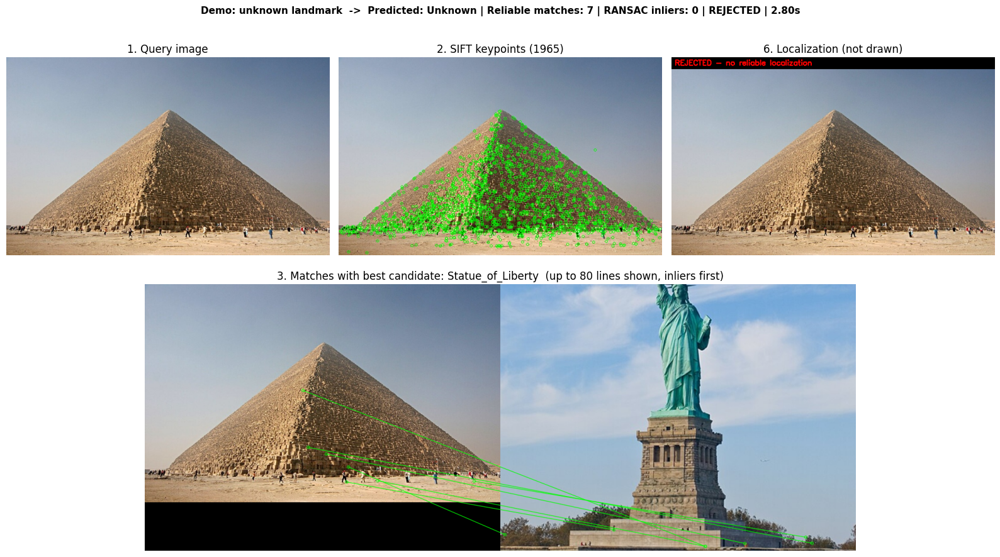

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1   Statue_of_Liberty                 7               0           False
    2        Eiffel_Tower                 6               0           False
    3           Colosseum                 5               0           False
    4           Taj_Mahal                 4               0           False
    5 Great_Wall_of_China                 3               0           False

Decision : REJECTED  (only 7 reliable matches (< 15))
Predicted: Unknown   | Reliable matches: 7 | Inliers: 0
Message  : Landmark rejected / geometric transformation unreliable - no polygon drawn.


In [9]:
# ---------- DEMO 2: a landmark that is NOT in the database (should be rejected) ----------
q = cv2.imread(f"{QUERY_DIR}/{UNKNOWN_NAME}_query.jpg")
res = recognize(q)
show_result(res, "Demo: unknown landmark", save_as="demo_rejected.png")

## Task 6 – Performance Evaluation

In [10]:
def make_conditions(base):
    return {
        "Original":            base,
        "Rotated (30 deg)":    rotate(base, 30),
        "Resized (50%)":       resize_scale(base, 0.5),
        "Reduced brightness":  darken(base, 0.4),
        "Different viewpoint": persp(base, 1.0, "right"),
    }

rows, gallery = [], []
for name in LANDMARKS:
    base = cv2.imread(QUERY_BASE[name])
    for cond, im in make_conditions(base).items():
        r = recognize(im)
        correct = r["recognized"] and r["predicted"] == name
        rows.append({"Query (true landmark)": name, "Condition": cond, "Predicted": r["predicted"],
                     "Keypoints": r["n_kp"], "Reliable matches": r["n_good"], "RANSAC inliers": r["n_inliers"],
                     "Decision": "Recognized" if r["recognized"] else "Rejected",
                     "Correct": "Yes" if correct else "No", "Time (s)": round(r["time"], 3)})
        if name == demo_name:
            gallery.append((cond, r))

# unknown landmark (not in DB) - correct behaviour = Rejected
unk_base = cv2.imread(f"{QUERY_DIR}/{UNKNOWN_NAME}_query.jpg")
for cond, im in {"Unknown - original": unk_base, "Unknown - resized 50%": resize_scale(unk_base, 0.5)}.items():
    r = recognize(im)
    rows.append({"Query (true landmark)": UNKNOWN_NAME + " (not in DB)", "Condition": cond, "Predicted": r["predicted"],
                 "Keypoints": r["n_kp"], "Reliable matches": r["n_good"], "RANSAC inliers": r["n_inliers"],
                 "Decision": "Recognized" if r["recognized"] else "Rejected",
                 "Correct": "Yes" if not r["recognized"] else "No", "Time (s)": round(r["time"], 3)})
    if cond == "Unknown - original":
        gallery.append(("Not in database", r))

results = pd.DataFrame(rows)
results.to_csv(f"{OUT_DIR}/experimental_results.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(results.to_string(index=False))
acc = (results["Correct"] == "Yes").mean() * 100
print(f"\nOverall correct decisions: {(results['Correct']=='Yes').sum()}/{len(results)}  ({acc:.1f}%)")
print(f"Average processing time  : {results['Time (s)'].mean():.3f} s per query")

       Query (true landmark)             Condition         Predicted  Keypoints  Reliable matches  RANSAC inliers   Decision Correct  Time (s)
                Eiffel_Tower              Original      Eiffel_Tower       1527               736             696 Recognized     Yes     2.150
                Eiffel_Tower      Rotated (30 deg)      Eiffel_Tower       1761               838             773 Recognized     Yes     2.510
                Eiffel_Tower         Resized (50%)      Eiffel_Tower        375               244             232 Recognized     Yes     0.528
                Eiffel_Tower    Reduced brightness      Eiffel_Tower        958               476             442 Recognized     Yes     1.366
                Eiffel_Tower   Different viewpoint      Eiffel_Tower       1539               807             750 Recognized     Yes     2.285
                   Taj_Mahal              Original           Unknown       2862                69              11   Rejected      No     4.131

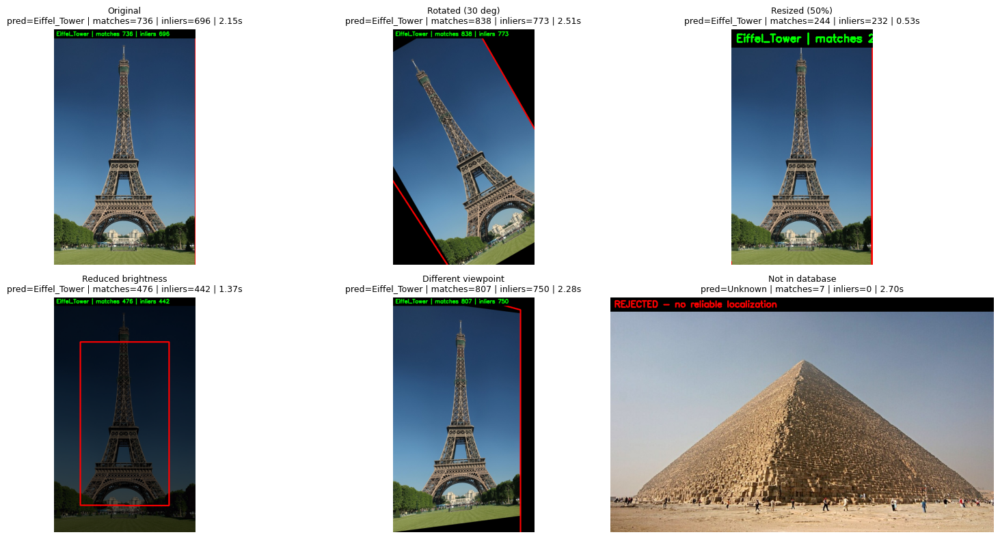

Condition
Different viewpoint      3/5
Original                 3/5
Reduced brightness       3/5
Resized (50%)            3/5
Rotated (30 deg)         3/5
Unknown - original       1/1
Unknown - resized 50%    1/1


In [11]:
# Visual summary of the six test conditions for one landmark
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (cond, r) in zip(axes.ravel(), gallery):
    ax.imshow(cv2.cvtColor(annotate(r), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f'{cond}\npred={r["predicted"]} | matches={r["n_good"]} | inliers={r["n_inliers"]} | {r["time"]:.2f}s', fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task6_six_conditions.png", dpi=100); plt.show()

# Per-condition accuracy
print(results.groupby("Condition")["Correct"].apply(lambda s: f"{(s=='Yes').sum()}/{len(s)}").to_string())

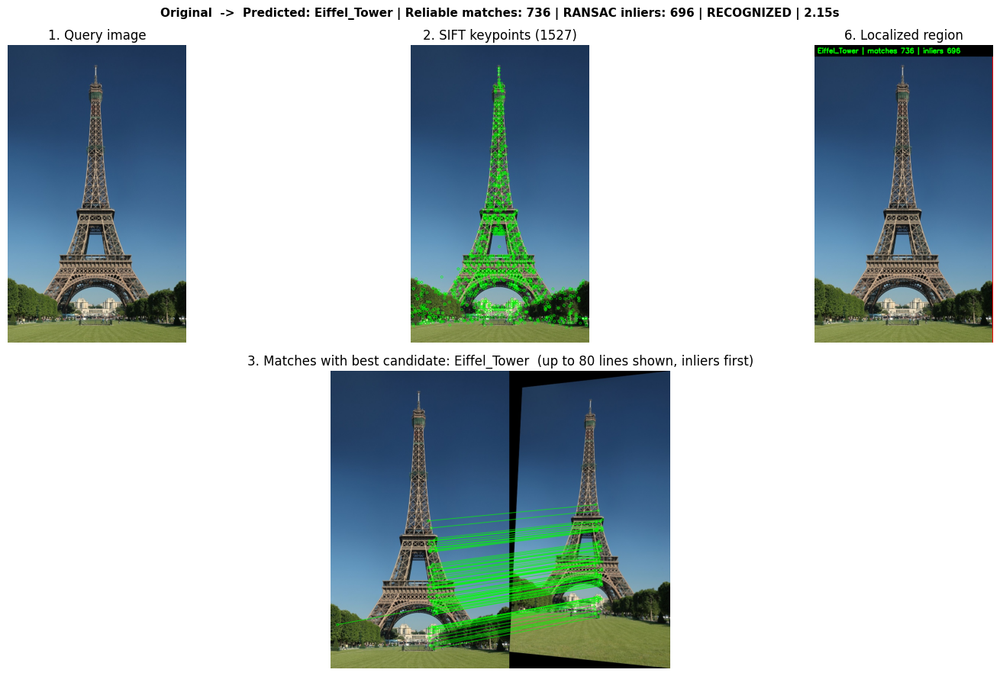

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1        Eiffel_Tower               736             696            True
    2           Taj_Mahal                 7               0           False
    3           Colosseum                 7               0           False
    4   Statue_of_Liberty                 7               0           False
    5 Great_Wall_of_China                 4               0           False

Decision : RECOGNIZED  (passed match threshold, RANSAC and margin tests)
Predicted: Eiffel_Tower   | Reliable matches: 736 | Inliers: 696


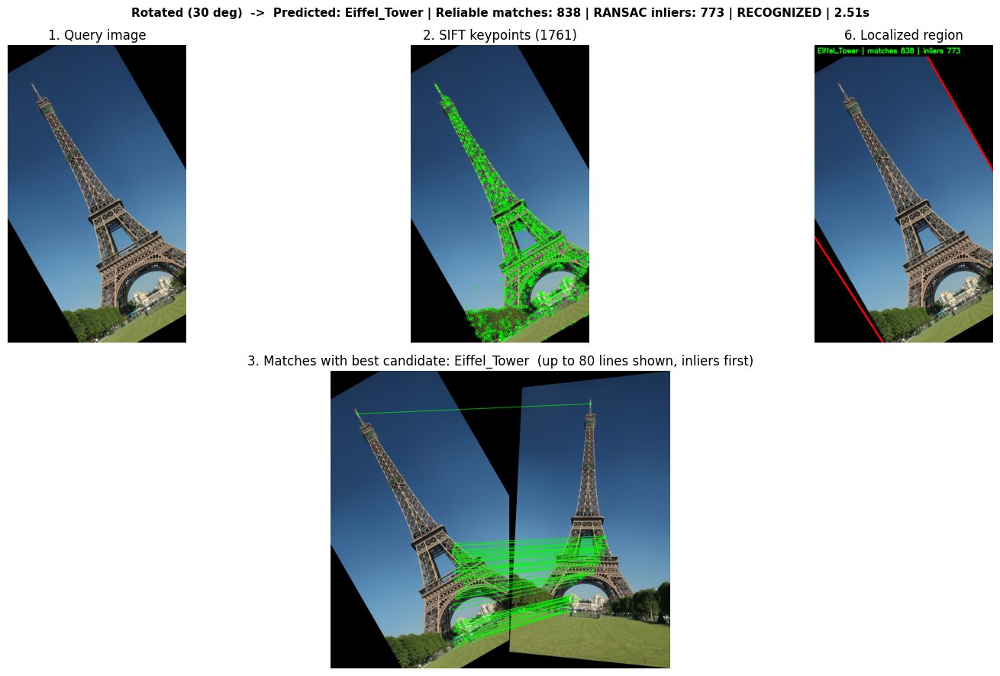

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1        Eiffel_Tower               838             773            True
    2           Taj_Mahal                17               5           False
    3           Colosseum                10               6           False
    4   Statue_of_Liberty                10               4           False
    5 Great_Wall_of_China                 7               0           False

Decision : RECOGNIZED  (passed match threshold, RANSAC and margin tests)
Predicted: Eiffel_Tower   | Reliable matches: 838 | Inliers: 773


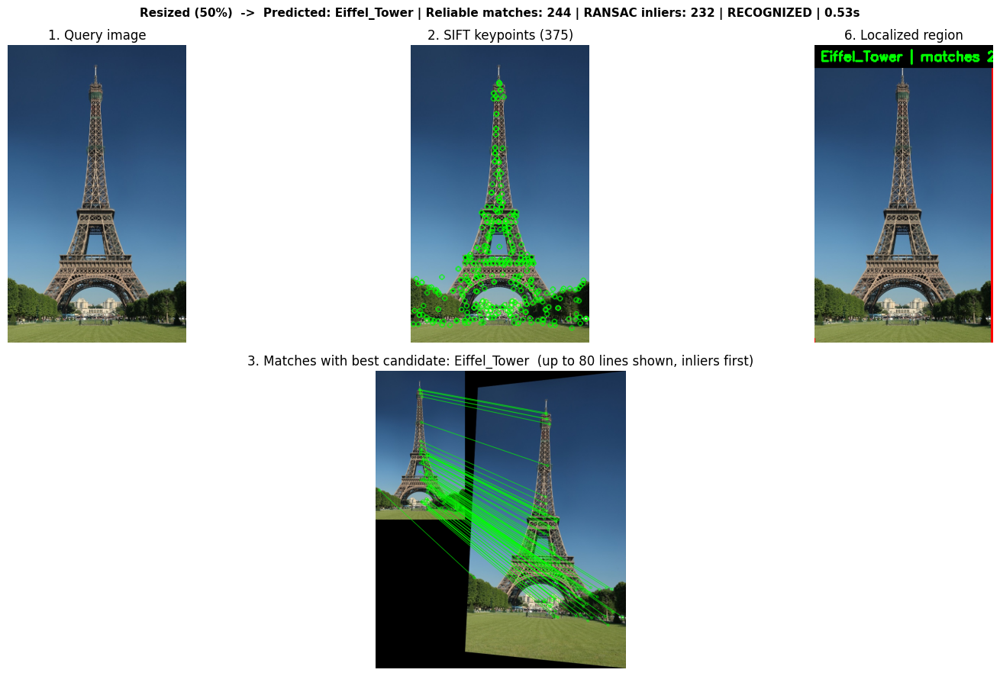

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1        Eiffel_Tower               244             232            True
    2   Statue_of_Liberty                 9               4           False
    3 Great_Wall_of_China                 4               0           False
    4           Colosseum                 3               0           False
    5           Taj_Mahal                 1               0           False

Decision : RECOGNIZED  (passed match threshold, RANSAC and margin tests)
Predicted: Eiffel_Tower   | Reliable matches: 244 | Inliers: 232


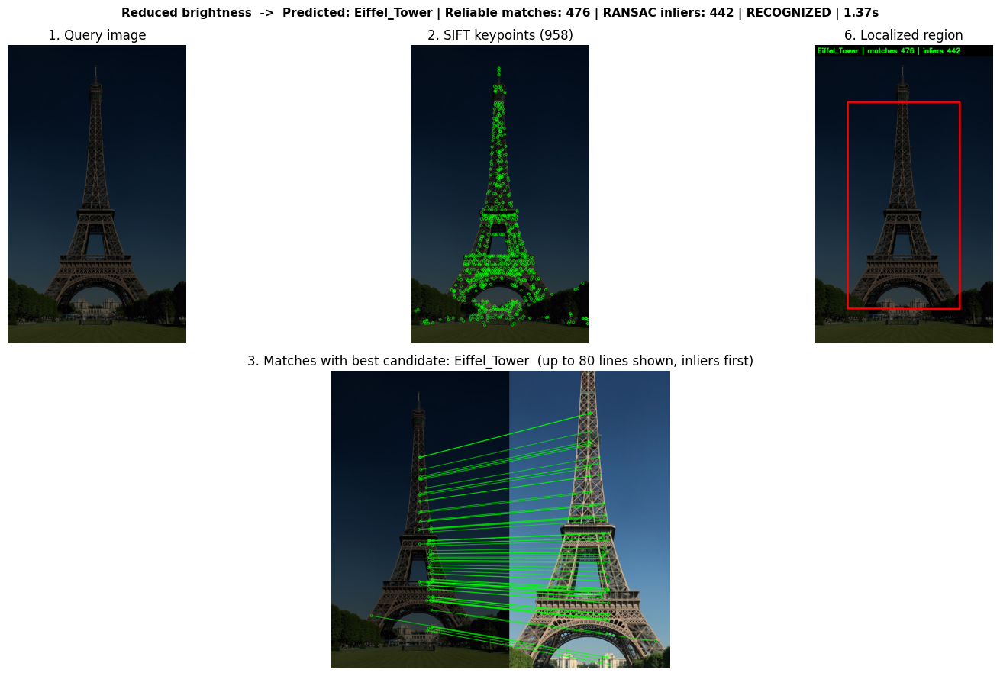

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1        Eiffel_Tower               476             442            True
    2           Colosseum                 5               0           False
    3   Statue_of_Liberty                 5               0           False
    4           Taj_Mahal                 3               0           False
    5 Great_Wall_of_China                 2               0           False

Decision : RECOGNIZED  (passed match threshold, RANSAC and margin tests)
Predicted: Eiffel_Tower   | Reliable matches: 476 | Inliers: 442


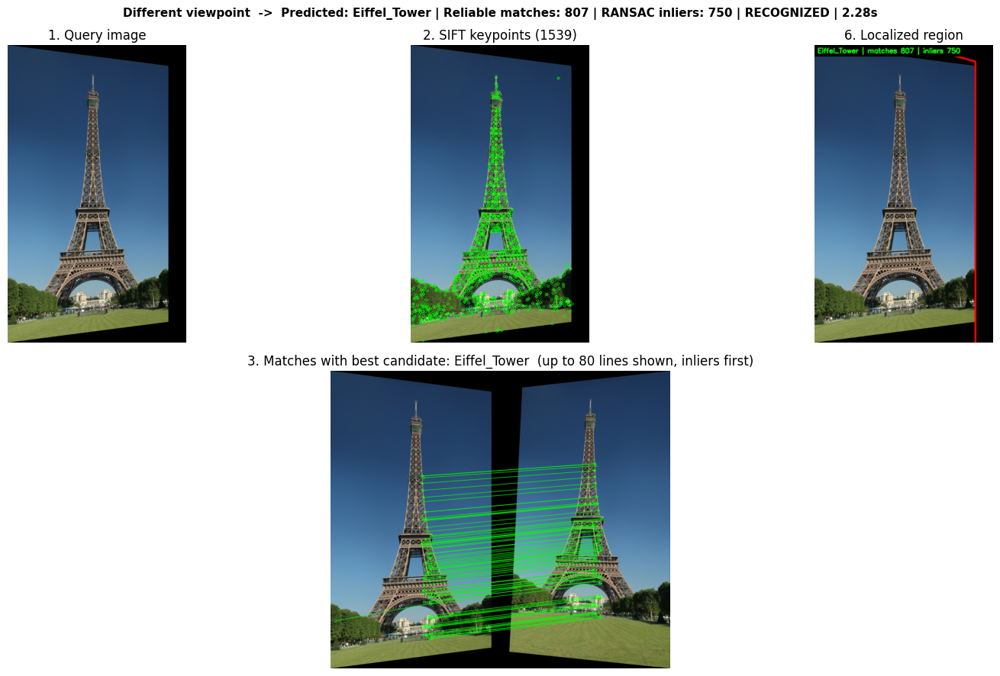

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1        Eiffel_Tower               807             750            True
    2           Taj_Mahal                16               6           False
    3           Colosseum                13               7            True
    4   Statue_of_Liberty                10               4           False
    5 Great_Wall_of_China                 6               0           False

Decision : RECOGNIZED  (passed match threshold, RANSAC and margin tests)
Predicted: Eiffel_Tower   | Reliable matches: 807 | Inliers: 750


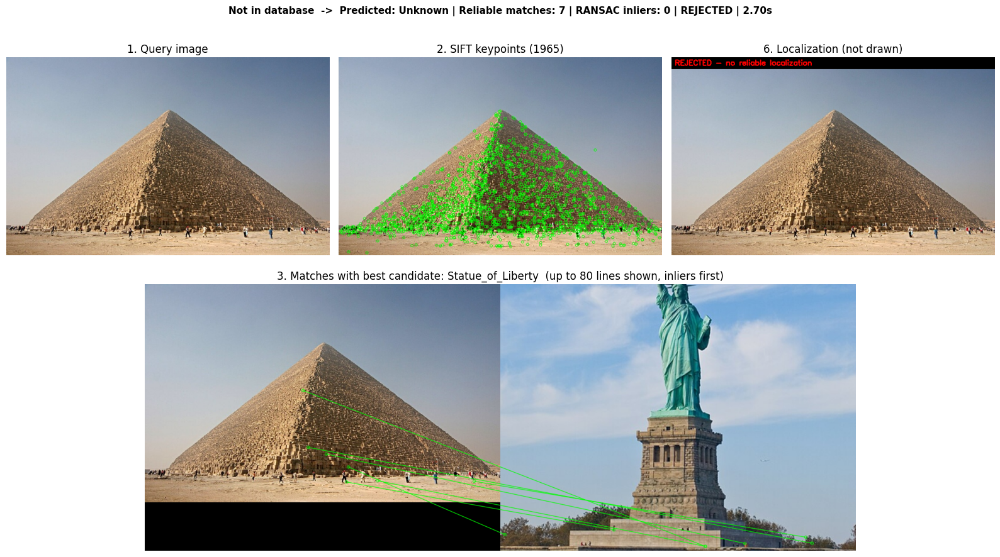

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1   Statue_of_Liberty                 7               0           False
    2        Eiffel_Tower                 6               0           False
    3           Colosseum                 5               0           False
    4           Taj_Mahal                 4               0           False
    5 Great_Wall_of_China                 3               0           False

Decision : REJECTED  (only 7 reliable matches (< 15))
Predicted: Unknown   | Reliable matches: 7 | Inliers: 0
Message  : Landmark rejected / geometric transformation unreliable - no polygon drawn.


In [12]:
# One detailed output screen per test condition (for your screenshots)
for cond, r in gallery:
    show_result(r, cond, save_as=f"result_{cond.replace(' ', '_').replace('(', '').replace(')', '').replace('%','pct')}.png")

In [13]:
# Zip the whole project (database + outputs) so you can download it for submission
shutil.make_archive("landmark_project_submission", "zip", ROOT)
print("Created landmark_project_submission.zip  (Colab: Files panel on the left -> right click -> Download)")

Created landmark_project_submission.zip  (Colab: Files panel on the left -> right click -> Download)


## Test With Your Own Image (final step – accuracy check)
Run this **last** cell, choose your landmark photo(s), and the system will predict the landmark.
Optionally set `TRUE_LABEL` to the real landmark name so the notebook tells you if the prediction was correct.

Choose one or more landmark images from your computer...


Saving images.jpg to images.jpg


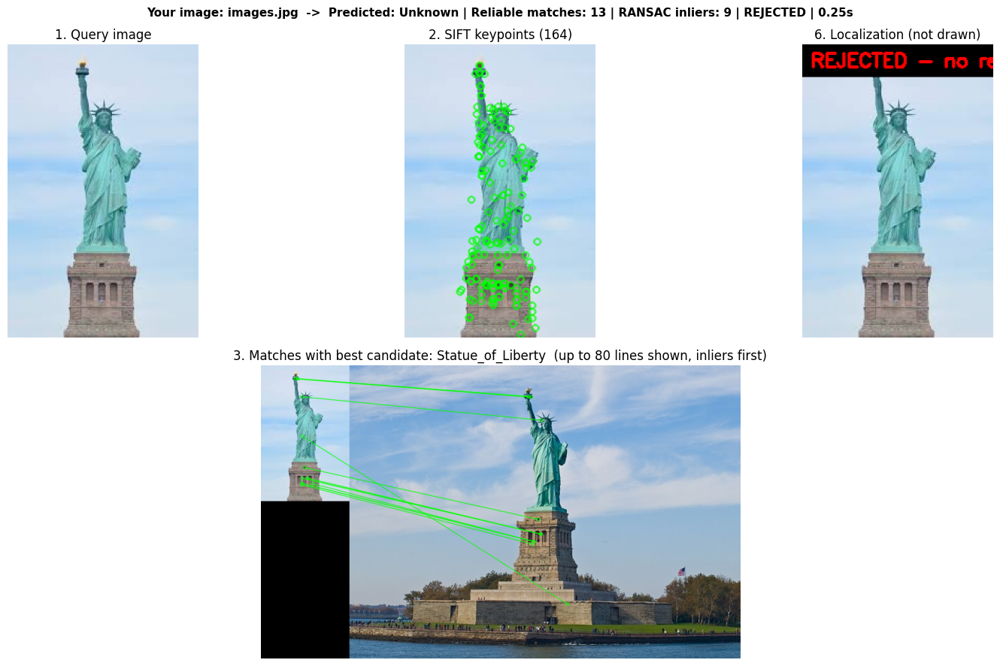

 Rank            Landmark  Reliable_matches  RANSAC_inliers  Valid_geometry
    1   Statue_of_Liberty                13               9           False
    2        Eiffel_Tower                 9               6           False
    3 Great_Wall_of_China                 4               0           False
    4           Taj_Mahal                 3               0           False
    5           Colosseum                 2               0           False

Decision : REJECTED  (only 13 reliable matches (< 15))
Predicted: Unknown   | Reliable matches: 13 | Inliers: 9
Message  : Landmark rejected / geometric transformation unreliable - no polygon drawn.

=== YOUR IMAGE RESULTS ===
      File Predicted  Keypoints  Reliable matches  RANSAC inliers Decision  Time (s)
images.jpg   Unknown        164                13               9 Rejected     0.255


In [14]:
# Valid labels: Eiffel_Tower, Taj_Mahal, Colosseum, Statue_of_Liberty, Great_Wall_of_China
# Use "Unknown" if your photo shows a landmark that is NOT in the database. Leave "" if you don't want a check.
TRUE_LABEL = ""

try:
    from google.colab import files
    print("Choose one or more landmark images from your computer...")
    up = files.upload()
    names = list(up.keys())
except Exception as e:
    print("Upload widget not available (", type(e).__name__, ") - using the built-in Taj_Mahal query instead.")
    names = [QUERY_BASE["Taj_Mahal"]]

if not names:
    print("No file selected.")

my_rows = []
for fn in names:
    im = cv2.imread(fn)
    if im is None:
        print("Could not read", fn); continue
    r = recognize(im)
    show_result(r, f"Your image: {os.path.basename(fn)}", save_as=f"upload_{os.path.splitext(os.path.basename(fn))[0]}.png")
    row = {"File": os.path.basename(fn), "Predicted": r["predicted"], "Keypoints": r["n_kp"],
           "Reliable matches": r["n_good"], "RANSAC inliers": r["n_inliers"],
           "Decision": "Recognized" if r["recognized"] else "Rejected", "Time (s)": round(r["time"], 3)}
    if TRUE_LABEL:
        row["True label"] = TRUE_LABEL
        row["Correct"] = "Yes" if r["predicted"] == TRUE_LABEL else "No"
    my_rows.append(row)

if my_rows:
    my_df = pd.DataFrame(my_rows)
    print("\n=== YOUR IMAGE RESULTS ===")
    print(my_df.to_string(index=False))
    if TRUE_LABEL:
        print(f"\nAccuracy on your images: {(my_df['Correct']=='Yes').sum()}/{len(my_df)}")
    my_df.to_csv(f"{OUT_DIR}/my_image_results.csv", index=False)